<a href="https://colab.research.google.com/github/lakshuu-jay/Projects/blob/main/K_MeansClusteringForCustomer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
 4   cluster                 200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 9.4+ KB


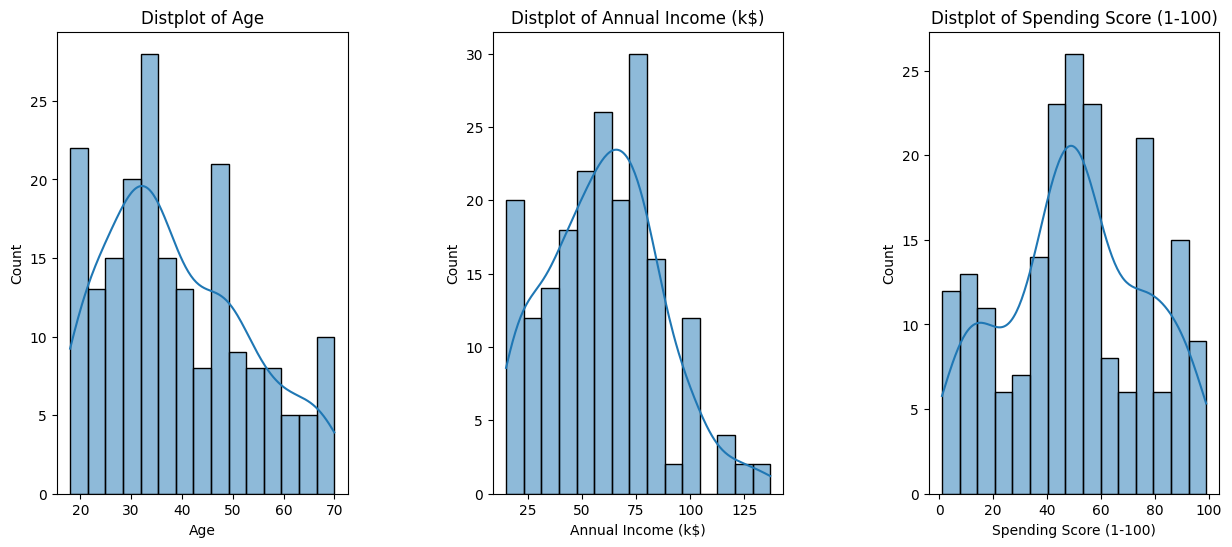

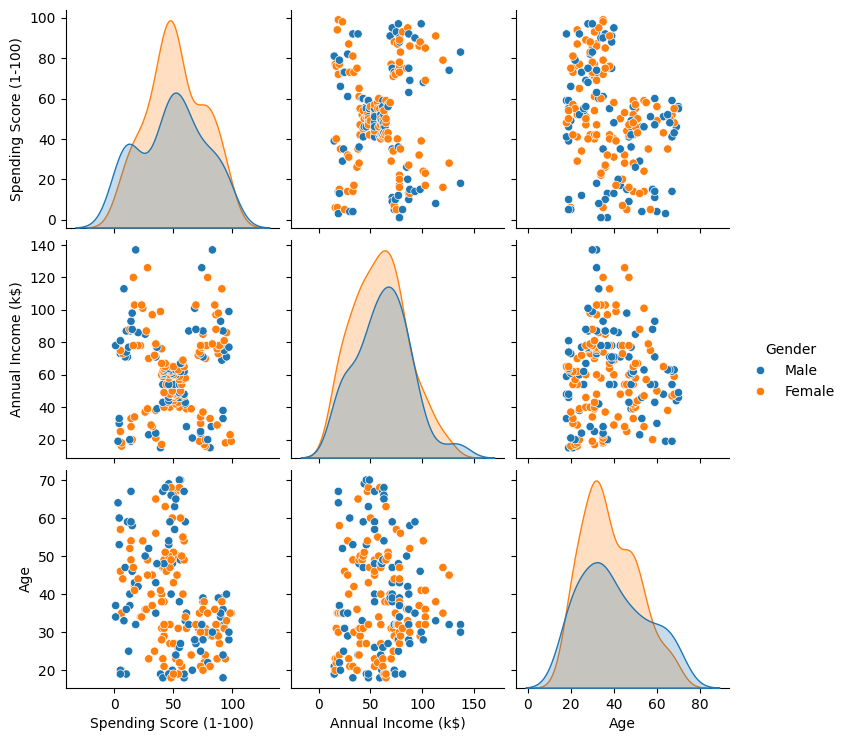

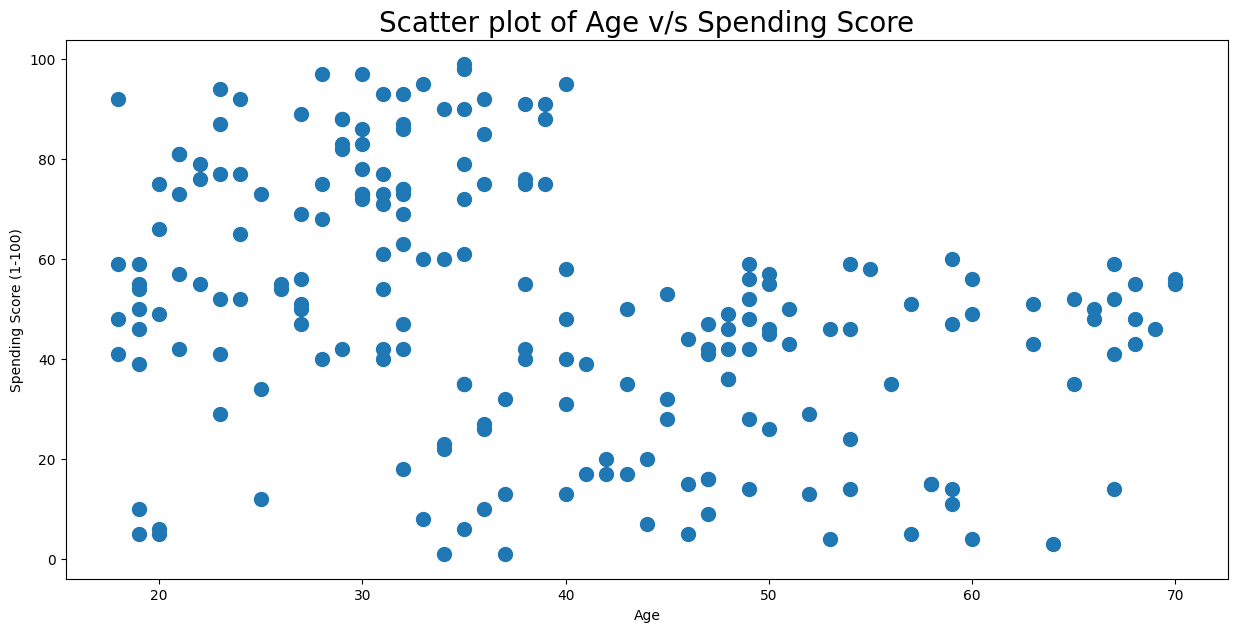

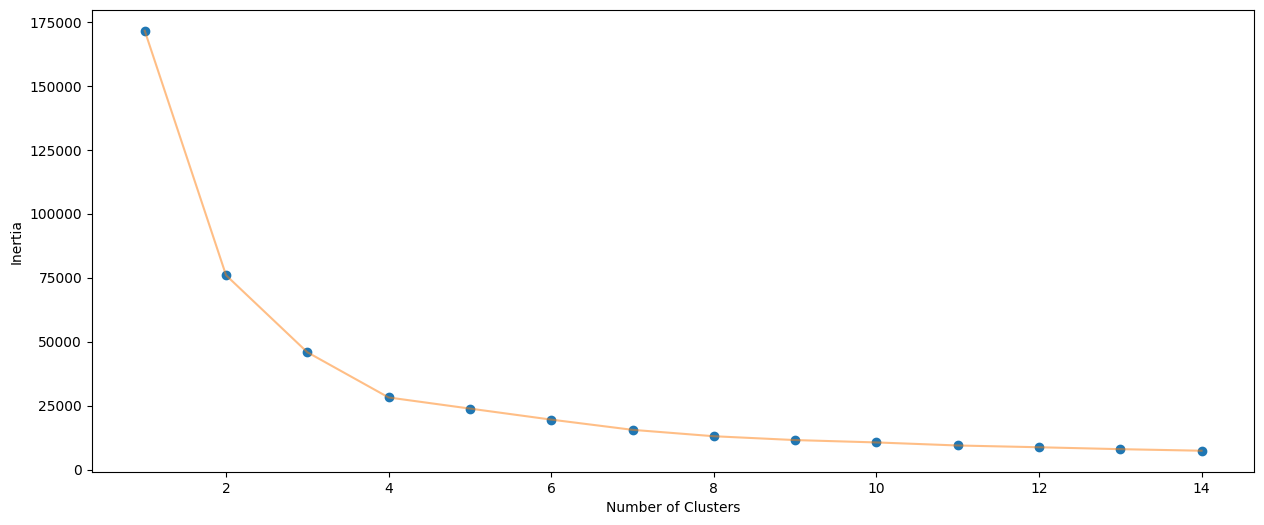

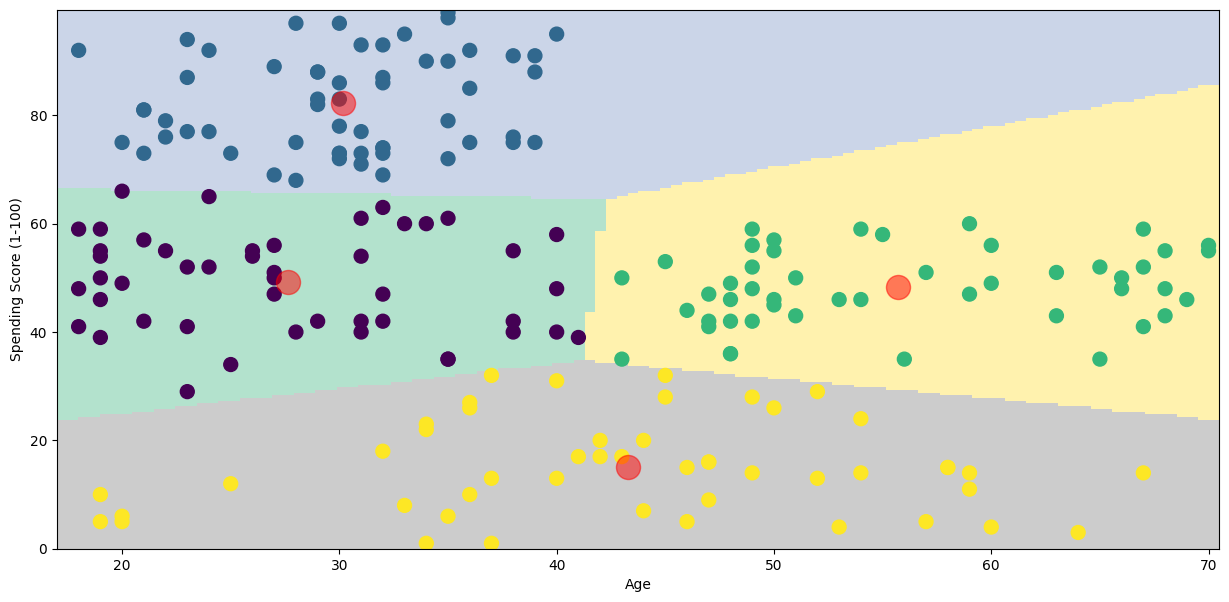

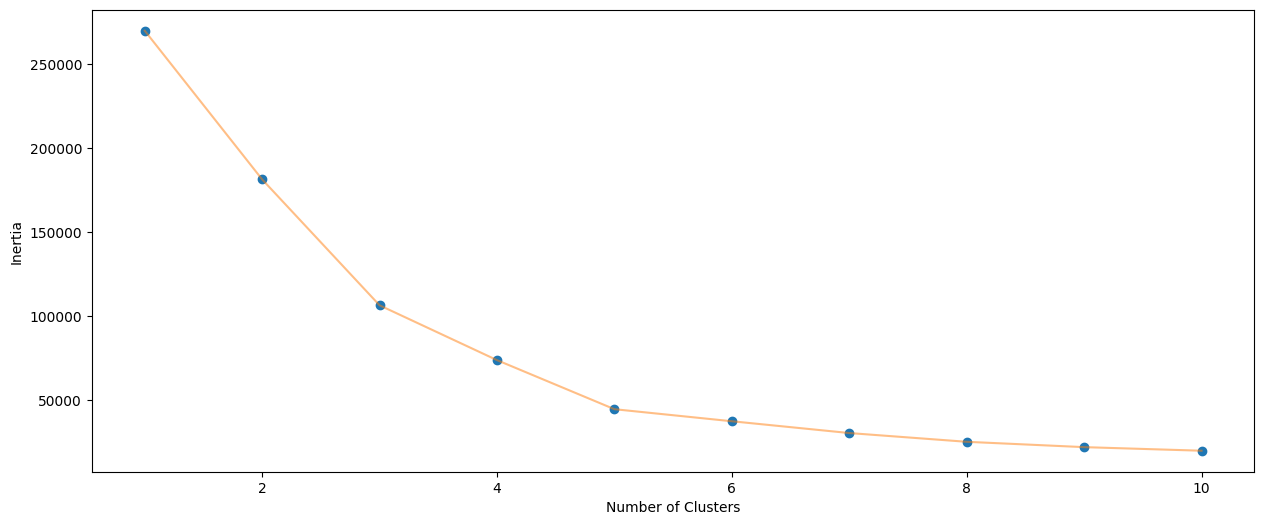

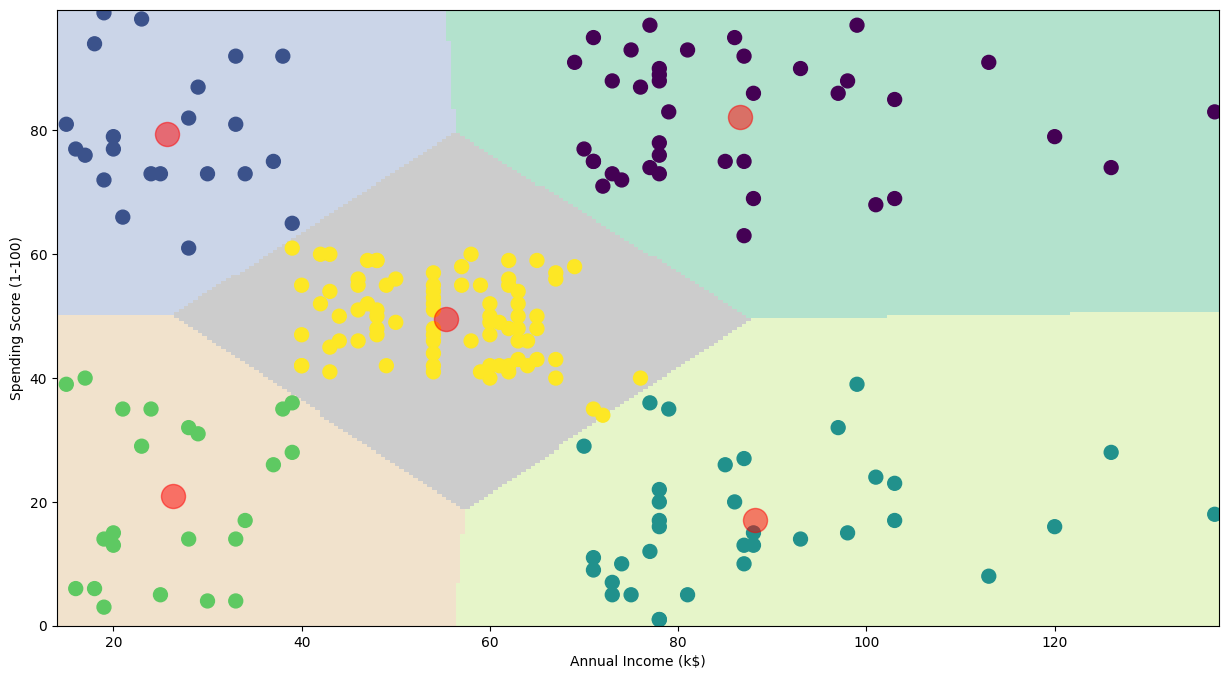

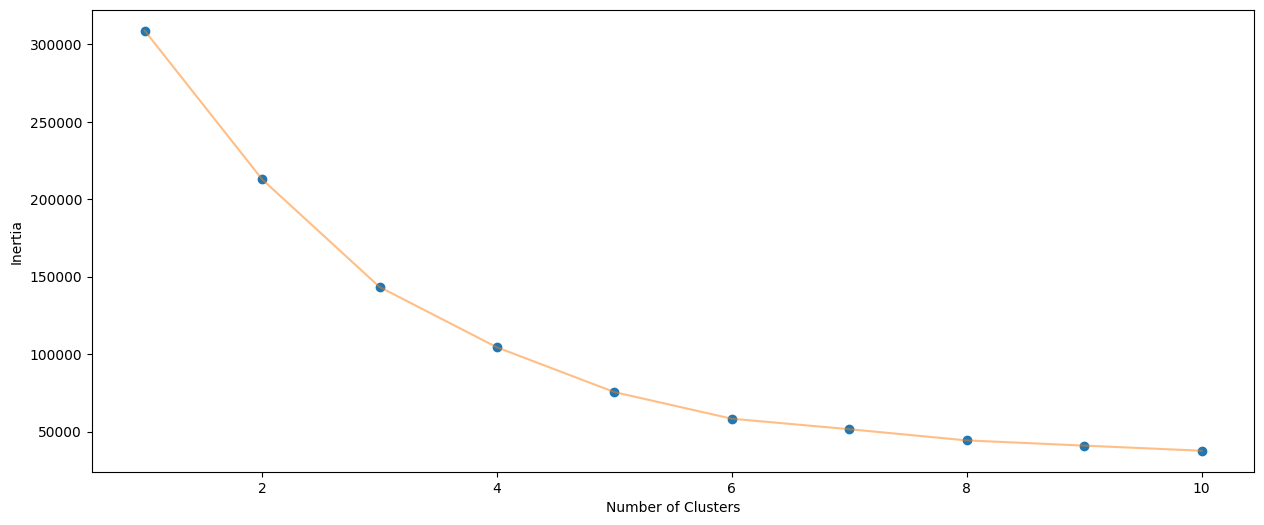

,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
CustomerID,,,,,
1,Male,19,15,39,4
2,Male,21,15,81,5
3,Female,20,16,6,4
4,Female,23,16,77,5
5,Female,31,17,40,4


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as py
import plotly.graph_objs as go
from sklearn.cluster import KMeans
import warnings

warnings.filterwarnings('ignore')
df = pd.read_csv('customers.csv', index_col=0)

df.head()
df.columns
df.info()
df.describe()
df.isnull().sum()

plt.figure(1, figsize=(15, 6))
n = 0

for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(df[x], bins=15, kde=True)
    plt.title('Distplot of {}'.format(x))

plt.show()

sns.pairplot(
    df,
    vars=['Spending Score (1-100)', 'Annual Income (k$)', 'Age'],
    hue='Gender'
)
plt.show()

plt.figure(figsize=(15, 7))
plt.title('Scatter plot of Age v/s Spending Score', fontsize=20)
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.scatter(df['Age'], df['Spending Score (1-100)'], s=100)
plt.show()

x1 = df[['Age', 'Spending Score (1-100)']].values
inertia = []

for n in range(1, 15):
    algorithm = KMeans(
        n_clusters=n, init='k-means++', n_init=10,
        max_iter=300, tol=0.0001, random_state=111,
        algorithm='elkan'
    )
    algorithm.fit(x1)
    inertia.append(algorithm.inertia_)

plt.figure(figsize=(15, 6))
plt.plot(np.arange(1, 15), inertia, 'o')
plt.plot(np.arange(1, 15), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()
algorithm = KMeans(
    n_clusters=4, init='k-means++', n_init=10,
    max_iter=300, tol=0.0001, random_state=111,
    algorithm='elkan'
)
algorithm.fit(x1)

labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_

h = 0.5
x_min, x_max = x1[:, 0].min() - 1, x1[:, 0].max() + 1
y_min, y_max = x1[:, 1].min() - 1, x1[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

Z = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])

plt.figure(figsize=(15, 7))
z = Z.reshape(xx.shape)

plt.imshow(
    z, interpolation='nearest',
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Pastel2, aspect='auto', origin='lower'
)

plt.scatter(x1[:, 0], x1[:, 1], c=labels1, s=100)
plt.scatter(
    centroids1[:, 0], centroids1[:, 1],
    s=300, c='red', alpha=0.5
)
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.show()

x2 = df[['Annual Income (k$)', 'Spending Score (1-100)']].values
inertia = []

for n in range(1, 11):
    algorithm = KMeans(
        n_clusters=n, init='k-means++', n_init=10,
        max_iter=300, tol=0.0001, random_state=111,
        algorithm='elkan'
    )
    algorithm.fit(x2)
    inertia.append(algorithm.inertia_)

plt.figure(figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

algorithm = KMeans(
    n_clusters=5, init='k-means++', n_init=10,
    max_iter=300, tol=0.0001, random_state=111,
    algorithm='elkan'
)
algorithm.fit(x2)

labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

h = 0.5
x_min, x_max = x2[:, 0].min() - 1, x2[:, 0].max() + 1
y_min, y_max = x2[:, 1].min() - 1, x2[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

Z2 = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])

plt.figure(figsize=(15, 8))
Z2 = Z2.reshape(xx.shape)

plt.imshow(
    Z2, interpolation='nearest',
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Pastel2, aspect='auto', origin='lower'
)

plt.scatter(x2[:, 0], x2[:, 1], c=labels2, s=100)
plt.scatter(
    centroids2[:, 0], centroids2[:, 1],
    s=300, c='red', alpha=0.5
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

X3 = df[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].values

inertia = []

for n in range(1, 11):
    algorithm = KMeans(
        n_clusters=n, init='k-means++', n_init=10,
        max_iter=300, tol=0.0001, random_state=111,
        algorithm='elkan'
    )
    algorithm.fit(X3)
    inertia.append(algorithm.inertia_)

plt.figure(figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

algorithm = KMeans(
    n_clusters=6, init='k-means++', n_init=10,
    max_iter=300, tol=0.0001, random_state=111,
    algorithm='elkan'
)
algorithm.fit(X3)

labels3 = algorithm.labels_
centroids3 = algorithm.cluster_centers_

df['cluster'] = labels3
df.head()

trace1 = go.Scatter3d(
    x=df['Age'],
    y=df['Spending Score (1-100)'],
    z=df['Annual Income (k$)'],
    mode='markers',
    marker=dict(
        color=df['cluster'],
        size=10,
        line=dict(
            color=df['cluster'],
            width=1
        ),
        opacity=0.8
    )
)

data = [trace1]

layout = go.Layout(
    title='Clusters wrt Age, Income and Spending Scores',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    )
)

fig = go.Figure(data=data, layout=layout)
fig.show()

df.head()
